## Step 1: Libraries Import & Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')
file_name = 'BlinkIT Grocery Data.xlsx'
df = pd.read_excel(file_name)

print("Data Loaded Successfully!")
print("Shape of Data:", df.shape)
display(df.head())

Data Loaded Successfully!
Shape of Data: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


## Step 2: Explore the Dataset 

In [ ]:
df.info()

display(df.describe())

print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

## Step 3: Clean & Preprocess Data 

In [2]:
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

df['Item Weight'] = df['Item Weight'].fillna(
    df.groupby('Item Type')['Item Weight'].transform('mean')
)

current_year = 2026
df['Outlet Age'] = current_year - df['Outlet Establishment Year']

print("Cleaned Fat Content Categories:\n", df['Item Fat Content'].value_counts())
print("\nRemaining Missing Values:\n", df.isnull().sum())

Cleaned Fat Content Categories:
 Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Remaining Missing Values:
 Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
Outlet Age                   0
dtype: int64


## Step 4: Executive KPI Cards 

In [5]:
total_sales = df['Sales'].sum()
avg_sales = df['Sales'].mean()
total_items = len(df)
avg_rating = df['Rating'].mean()

print("=" * 60)
print(f" TOTAL SALES REVENUE     : ${total_sales:,.2f}")
print(f" AVERAGE SALES PER ITEM  : ${avg_sales:.2f}")
print(f" TOTAL ITEMS SOLD        : {total_items:,}")
print(f" AVERAGE ITEM RATING     : {avg_rating:.2f} / 5.0")
print("=" * 60)

 TOTAL SALES REVENUE     : $1,201,681.49
 AVERAGE SALES PER ITEM  : $140.99
 TOTAL ITEMS SOLD        : 8,523
 AVERAGE ITEM RATING     : 3.97 / 5.0


## 3. Data Visualizations, Insights & Recommendations
Chart 1: Total Sales by Item Fat Content (Donut Chart)

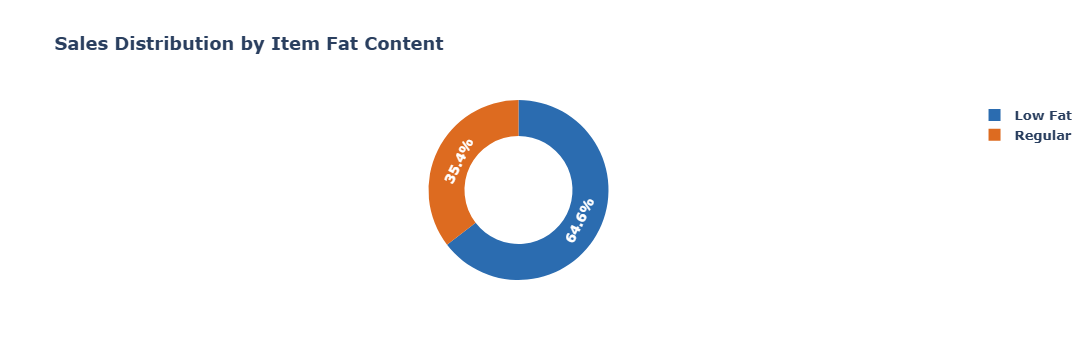

In [6]:
fat_sales = df.groupby('Item Fat Content')['Sales'].sum().reset_index()

fig1 = px.pie(
    fat_sales,
    values='Sales',
    names='Item Fat Content',
    hole=0.6,
    color='Item Fat Content',
    color_discrete_map={'Low Fat': '#2b6cb0', 'Regular': '#dd6b20'},
    title='<b>Sales Distribution by Item Fat Content</b>'
)
fig1.update_layout(font=dict(weight="bold", size=13))
fig1.show()

## Conclusion
Low Fat items dominate consumer demand, driving approximately 64.6% ($776K) of overall sales, while Regular items account for 35.4% ($425K).

This reflects a strong consumer preference toward healthier grocery options.

## Chart 2: Top 10 Item Categories by Revenue (Horizontal Bar Chart)

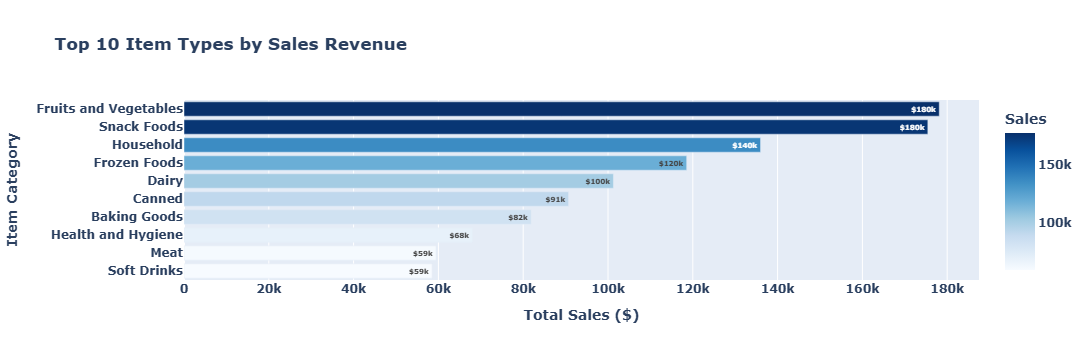

In [7]:
top_items = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False).head(10).reset_index()

fig2 = px.bar(
    top_items,
    x='Sales',
    y='Item Type',
    orientation='h',
    text_auto='$,.2s',
    color='Sales',
    color_continuous_scale='Blues',
    title='<b>Top 10 Item Types by Sales Revenue</b>'
)
fig2.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    xaxis_title='<b>Total Sales ($)</b>',
    yaxis_title='<b>Item Category</b>',
    font=dict(weight="bold")
)
fig2.show()

## Conclusion
Fruits and Vegetables ($178K) and Snack Foods ($175K) are the primary revenue drivers, followed closely by Household essentials ($136K) and Frozen Foods ($119K).

## Chart 3: Outlet Type Performance (Sales vs. Item Volume)

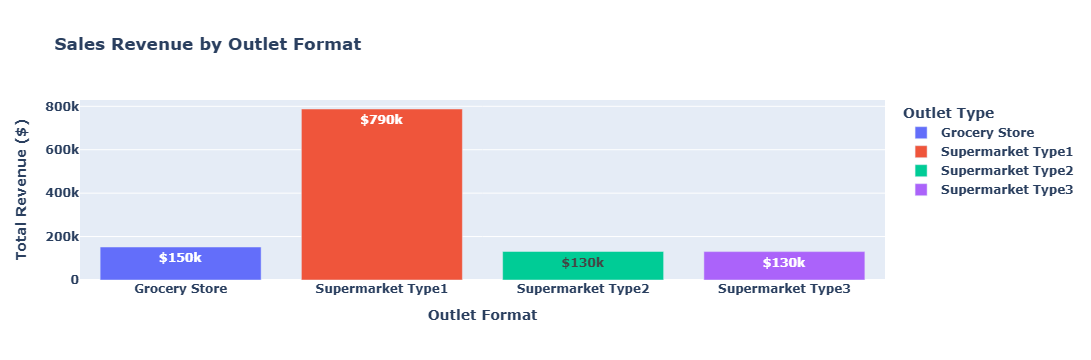

In [8]:
outlet_perf = df.groupby('Outlet Type').agg(
    Total_Sales=('Sales', 'sum'),
    Avg_Sales=('Sales', 'mean'),
    Item_Count=('Sales', 'count')
).reset_index()

fig3 = px.bar(
    outlet_perf,
    x='Outlet Type',
    y='Total_Sales',
    text_auto='$,.2s',
    color='Outlet Type',
    title='<b>Sales Revenue by Outlet Format</b>'
)
fig3.update_layout(
    xaxis_title='<b>Outlet Format</b>',
    yaxis_title='<b>Total Revenue ($)</b>',
    font=dict(weight="bold")
)
fig3.show()

## Conclusion
Supermarket Type1 is the cornerstone of distribution, accounting for over 65.5% ($788K) of gross revenue across 5,577 transaction lines.

Standard Grocery Stores underperform significantly in volume compared to supermarket configurations.

## Chart 4: Sales Revenue Across City Tiers (Sunburst Hierarchy)

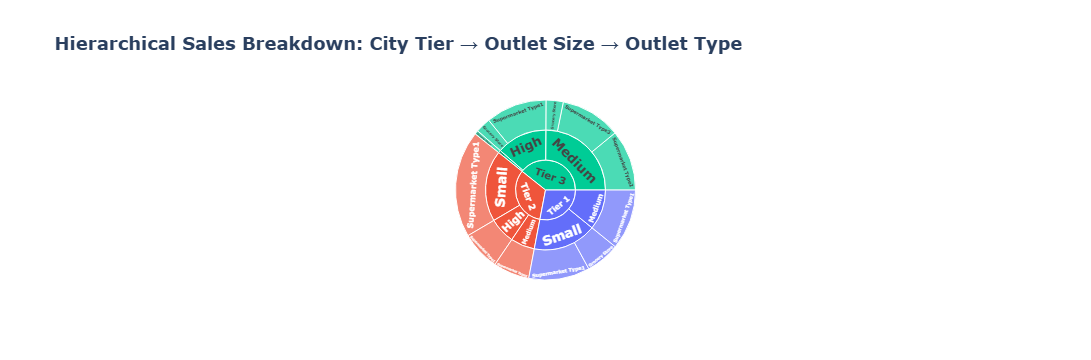

In [9]:
fig4 = px.sunburst(
    df,
    path=['Outlet Location Type', 'Outlet Size', 'Outlet Type'],
    values='Sales',
    color='Outlet Location Type',
    title='<b>Hierarchical Sales Breakdown: City Tier → Outlet Size → Outlet Type</b>'
)
fig4.update_layout(font=dict(weight="bold", size=13))
fig4.show()

## Conclusion
Tier 3 cities generate the highest aggregate sales ($472K), followed by Tier 2 ($393K) and Tier 1 ($336K), proving substantial demand beyond metropolitan regions.

Medium-sized outlets strike the best balance between inventory capacity and operational throughput.

## Chart 5: Correlation Matrix (Numerical Attributes)

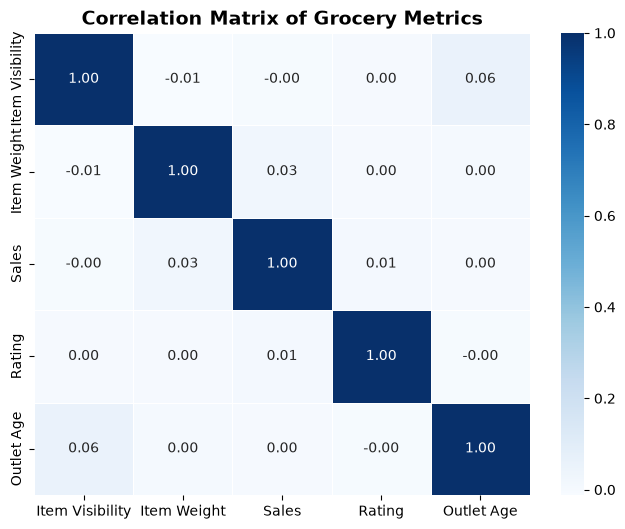

In [10]:
num_cols = ['Item Visibility', 'Item Weight', 'Sales', 'Rating', 'Outlet Age']
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Correlation Matrix of Grocery Metrics', fontsize=14, fontweight='bold')
plt.show()

## Conclusion
Item Visibility shows no strong positive linear correlation with gross sales, indicating that high shelf presence alone does not guarantee sales volume unless paired with competitive pricing and product relevance.